**Goal.** Put rectangular packages into one container so that the **total weight loaded is as large as possible**. Boxes must not overlap, must stay inside the container, and the total weight must stay under the limit. Rotating a box by 90 degrees is allowed where permitted.

**NOTE.** I did not write the final method in one go. I ran an idea, looked at the result, found what was wrong, and that problem became the next idea. Every step below follows the same pattern:

> **Thought** (why I am trying this) -> **Code** -> **Result** -> **What I observed** -> **Conclusion** -> **Next thought** (which becomes the next step)

In [1]:
%pip install -q dimod dwave-neal ortools

import itertools, math, time, json, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import dimod, neal
from ortools.sat.python import cp_model

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
os.makedirs('results', exist_ok=True)
JOURNEY = []      # one line per version, all on the same large dataset; filled in as we go

## Step 0: The problem and the data

I need test data I can repeat. I initialy made a  generator fucntion that made random packages, so every run gave different numbers. I kept the same idea (sizes 10 to 40, weights 1 to 15) but added a **seed**, so the data is always the same.

* **large** = my original setup: 80 packages in a 100 x 100 x 100 container, weight limit 800. **The whole story below runs on this set.**
* **small** and **medium** are used later for the final comparison. Their containers are smaller so the packages really compete for space, and their weight limit is 75% of the total package weight, so *choosing* which packages to load matters.

Look at the first table: on **large**, the packages need 121% of the container volume, so not everything can fit. Also the total weight is 684, below the limit of 800, so on this set **only space** decides what we can load, never the weight limit.

In [2]:
def make_testset(name, n, seed, side, rot_prob=1.0, cap_frac=0.75, weight_capacity=None):
    rng = random.Random(seed)
    pkgs = []
    for i in range(n):
        pkgs.append({'package_id': f'PKG_{i+1:02d}',
                     'width': round(rng.uniform(10, 40)), 'length': round(rng.uniform(10, 40)),
                     'height': round(rng.uniform(10, 40)), 'weight': round(rng.uniform(1.0, 15.0)),
                     'allow_90_rotation': rng.random() < rot_prob})
    for p in pkgs:
        p['volume'] = p['width'] * p['length'] * p['height']
    total_w = sum(p['weight'] for p in pkgs)
    container = {'id': f'Container_{name}', 'width': side, 'length': side, 'height': side,
                 'weight_capacity': float(weight_capacity if weight_capacity else round(cap_frac * total_w))}
    return {'name': name, 'seed': seed, 'container': container, 'packages': pkgs}

TESTSETS = {
    'small':  make_testset('small',  12, 11,  55, rot_prob=0.8),
    'medium': make_testset('medium', 20, 22,  65, rot_prob=0.8),
    'large':  make_testset('large',  80, 80, 100, rot_prob=1.0, weight_capacity=800.0),   # your original setup
}
with open('results/test_dataset.json', 'w') as f:
    json.dump(TESTSETS, f, indent=2)
for k, ts in TESTSETS.items():
    pd.DataFrame(ts['packages']).to_csv(f'results/packages_{k}.csv', index=False)

def metrics(placed, container):
    cv = container['width'] * container['length'] * container['height']
    vol = sum(r['width'] * r['length'] * r['height'] for r in placed)
    wt = sum(r['weight'] for r in placed)
    return {'packed': len(placed), 'packed_volume': vol, 'vol_util': 100.0 * vol / cv,
            'packed_weight': wt, 'wt_util': 100.0 * wt / container['weight_capacity']}

rows = []
for k, ts in TESTSETS.items():
    C, P = ts['container'], ts['packages']
    cv = C['width'] * C['length'] * C['height']
    rows.append({'set': k, 'packages': len(P), 'container': f"{C['width']}x{C['length']}x{C['height']}",
                 'package volume / container volume %': round(sum(p['volume'] for p in P) / cv * 100, 1),
                 'total weight': sum(p['weight'] for p in P), 'weight capacity': C['weight_capacity'],
                 'rotation allowed for': sum(p['allow_90_rotation'] for p in P)})
display(pd.DataFrame(rows))

P_L, C_L = TESTSETS['large']['packages'], TESTSETS['large']['container']   # the dataset used for the whole story
def quick_look(name, placed, C, seconds):
    m = metrics(placed, C)
    print(f"{name}: packed {m['packed']} | volume used {m['vol_util']:.1f}% | weight used {m['wt_util']:.1f}% | time {seconds:.2f}s")

,set,packages,container,package volume / container volume %,total weight,weight capacity,rotation allowed for
0,small,12,55x55x55,89.2,108,81.0,9
1,medium,20,65x65x65,107.2,222,166.0,14
2,large,80,100x100x100,121.4,684,800.0,80


## Step 1: v1, the brute force approach (my first version)

**Thought.** Keep it simple. Sort the packages from heaviest to lightest (weight is what I want to maximise). Keep one pointer `(x, y, z)`. Put each package at the pointer, then move the pointer along. If a package does not fit, shift the pointer once and try again. If it still does not fit, skip the package.

This is my baseline which accepts that
1. the total volume of selected package is less than volume of container
2. to make sure that orientation of selected packages doesnt cross the boundary of container.

In [3]:
def _rot_v1(pkg):
    w, l, h = pkg['width'], pkg['length'], pkg['height']
    if not pkg.get('allow_90_rotation', False):
        return [(w, l, h)]
    return list(set([(w, l, h), (w, h, l), (l, w, h), (l, h, w), (h, w, l), (h, l, w)]))

def baseline_v1(packages, container):
    packages = sorted(packages, key=lambda x: x['weight'], reverse=True)
    container_volume = container['width'] * container['length'] * container['height']
    container_weight_limit = container['weight_capacity']
    placed_packages, total_used_volume, total_used_weight = [], 0, 0
    current_x, current_y, current_z = 0, 0, 0

    def record(pkg, orient, x, y, z):
        ow, ol, oh = orient
        return {'package_id': pkg['package_id'], 'width': ow, 'length': ol, 'height': oh,
                'weight': pkg['weight'], 'volume': pkg['volume'], 'x_pos': x, 'y_pos': y, 'z_pos': z,
                'rotated': orient != (pkg['width'], pkg['length'], pkg['height'])}

    for pkg in packages:
        if total_used_volume + pkg['volume'] > container_volume:
            continue
        if total_used_weight + pkg['weight'] > container_weight_limit:
            continue
        placed = False
        orientations = _rot_v1(pkg)
        for orient in orientations:                       # takes the FIRST rotation that fits
            ow, ol, oh = orient
            if (current_x + ow <= container['width'] and current_y + ol <= container['length']
                    and current_z + oh <= container['height']):
                placed_packages.append(record(pkg, orient, current_x, current_y, current_z))
                total_used_volume += pkg['volume']; total_used_weight += pkg['weight']
                current_x += ow; placed = True
                break
        if not placed:
            if placed_packages:
                last_pkg = placed_packages[-1]
                min_dim = min(last_pkg['width'], last_pkg['length'], last_pkg['height'])
                if current_x + pkg['width'] > container['width']:
                    current_x = 0; current_y += min_dim
                elif current_y + pkg['length'] > container['length']:
                    current_y = 0; current_z += min_dim
                else:
                    current_x += min_dim
                for orient in orientations:               # ONE shift attempt, then give up on this package
                    ow, ol, oh = orient
                    if (current_x + ow <= container['width'] and current_y + ol <= container['length']
                            and current_z + oh <= container['height']):
                        placed_packages.append(record(pkg, orient, current_x, current_y, current_z))
                        total_used_volume += pkg['volume']; total_used_weight += pkg['weight']
                        current_x += ow; placed = True
                        break
            else:
                continue
    return placed_packages

t0 = time.perf_counter()
placed_v1 = baseline_v1(P_L, C_L)
t_v1 = time.perf_counter() - t0
quick_look('v1 results', placed_v1, C_L, t_v1)

v1 results: packed 64 | volume used 99.9% | weight used 78.0% | time 0.00s


**Result.** 64 of 80 packages packed, **99.9% of the volume used**, 78% of the weight limit.

Honestly, that looks too good. Random boxes almost never fill 99.9% of a container. Now lets plot the 3d graph.

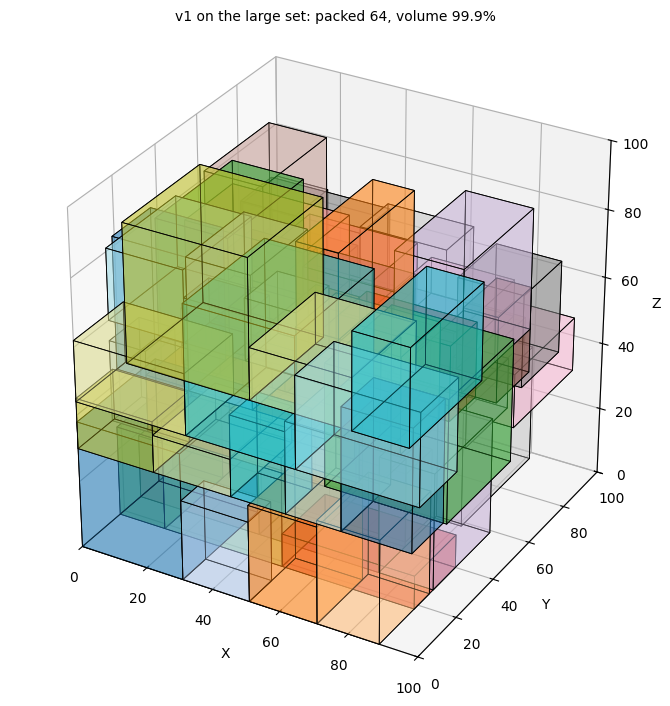

In [4]:
def draw_box(ax, x, y, z, dx, dy, dz, color, label=None, alpha=0.35, fontsize=8):
    v = [[x, y, z], [x+dx, y, z], [x+dx, y+dy, z], [x, y+dy, z],
         [x, y, z+dz], [x+dx, y, z+dz], [x+dx, y+dy, z+dz], [x, y+dy, z+dz]]
    faces = [[v[0], v[1], v[2], v[3]], [v[4], v[5], v[6], v[7]], [v[0], v[1], v[5], v[4]],
             [v[2], v[3], v[7], v[6]], [v[1], v[2], v[6], v[5]], [v[4], v[7], v[3], v[0]]]
    ax.add_collection3d(Poly3DCollection(faces, facecolors=color, edgecolors='black', linewidths=0.6, alpha=alpha))
    if label:
        ax.text(x + dx/2, y + dy/2, z + dz, str(label), ha='center', va='center', fontsize=fontsize, zorder=10,
                bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85))

def plot_packing(ax, placed, container, title, label_ids=True, fontsize=8):
    W, L, H = container['width'], container['length'], container['height']
    ax.set_xlim(0, W); ax.set_ylim(0, L); ax.set_zlim(0, H)
    cmap = plt.get_cmap('tab20')
    for i, r in enumerate(placed):
        draw_box(ax, r['x_pos'], r['y_pos'], r['z_pos'], r['width'], r['length'], r['height'], cmap(i % 20),
                 label=r['package_id'].split('_')[-1] if label_ids else None, fontsize=fontsize)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.set_box_aspect((W, L, H)); ax.set_title(title, fontsize=10)

def plot_one(placed, container, title, label_ids=False, fontsize=6):
    fig = plt.figure(figsize=(8, 7)); ax = fig.add_subplot(111, projection='3d')
    plot_packing(ax, placed, container, title, label_ids, fontsize); plt.tight_layout(); plt.show()

m = metrics(placed_v1, C_L)
plot_one(placed_v1, C_L, f"v1 on the large set: packed {m['packed']}, volume {m['vol_util']:.1f}%")

**What I observed.** In the 3D picture the boxes pass through each other. So the 99.9% cannot be real. I see three problems in my own code:

1. **Rotation.** I only take the *first* rotation that fits. I never ask which rotation is the *best*.
2. **Overlap.** I track the pointer `(x, y, z)`, but not where the earlier boxes are. When a row wraps around, a new box can land inside an old one.
3. **Skipped packages.** A package that fails one shift is dropped forever, even though it might fit somewhere else.

So this is a rough heuristic, not a careful deterministic method. Arguing by looking at pictures is not enough, so I build a **checker**: a small judge that looks at any finished layout and counts the violations (box outside the container, overlapping pairs, overweight, a rotation that is not allowed, duplicates). From now on, **no result counts until the checker agrees.**

In [5]:
def boxes_of(placed):
    return [(r['x_pos'], r['y_pos'], r['z_pos'], r['width'], r['length'], r['height']) for r in placed]

def boxes_overlap(a, b):
    return not (a[0]+a[3] <= b[0] or b[0]+b[3] <= a[0] or
                a[1]+a[4] <= b[1] or b[1]+b[4] <= a[1] or
                a[2]+a[5] <= b[2] or b[2]+b[5] <= a[2])

def validate(placed, container, packages):
    """The authority: checks a finished layout, no matter which method made it."""
    W, L, H = container['width'], container['length'], container['height']
    boxes = boxes_of(placed)
    oob = sum(1 for (x, y, z, w, l, h) in boxes if x < 0 or y < 0 or z < 0 or x+w > W or y+l > L or z+h > H)
    ov = sum(1 for i in range(len(boxes)) for j in range(i+1, len(boxes)) if boxes_overlap(boxes[i], boxes[j]))
    overweight = int(sum(r['weight'] for r in placed) > container['weight_capacity'] + 1e-9)
    by_id = {p['package_id']: p for p in packages}
    bad_orient = 0
    for r in placed:
        p = by_id[r['package_id']]
        dims, orig = (r['width'], r['length'], r['height']), (p['width'], p['length'], p['height'])
        if sorted(dims) != sorted(orig) or (not p.get('allow_90_rotation', False) and dims != orig):
            bad_orient += 1
    dup = len(placed) - len({r['package_id'] for r in placed})
    v = {'out_of_bounds': oob, 'overlapping_pairs': ov, 'overweight': overweight, 'bad_orientation': bad_orient, 'duplicates': dup}
    v['total_violations'] = sum(v.values())
    return v

def log_result(name, placed, C, P, seconds, note=''):
    """Print one line and remember it for the journey table at the end."""
    m, v = metrics(placed, C), validate(placed, C, P)
    JOURNEY.append({'version': name, 'packed': m['packed'], 'volume %': round(m['vol_util'], 1), 'weight %': round(m['wt_util'], 1),
                    'violations': v['total_violations'], 'seconds': round(seconds, 2), 'note': note})
    print(f"{name}: packed {m['packed']} | volume {m['vol_util']:.1f}% | weight {m['wt_util']:.1f}% | "
          f"violations {v['total_violations']} (overlapping pairs {v['overlapping_pairs']}) | {seconds:.2f}s")

# v1 on all three test sets
rows = []
for k, ts in TESTSETS.items():
    t0 = time.perf_counter(); pl = baseline_v1(ts['packages'], ts['container']); dt = time.perf_counter() - t0
    m, v = metrics(pl, ts['container']), validate(pl, ts['container'], ts['packages'])
    rows.append({'set': k, 'packed': m['packed'], 'volume % (claimed)': round(m['vol_util'], 1), 'overlapping pairs': v['overlapping_pairs'],
                 'out of bounds': v['out_of_bounds'], 'total violations': v['total_violations']})
display(pd.DataFrame(rows))
log_result('v1', placed_v1, C_L, P_L, t_v1, 'first idea')

,set,packed,volume % (claimed),overlapping pairs,out of bounds,total violations
0,small,7,62.1,8,0,8
1,medium,13,67.6,18,0,18
2,large,64,99.9,185,0,185


v1: packed 64 | volume 99.9% | weight 78.0% | violations 185 (overlapping pairs 185) | 0.00s


**Conclusion.**

* v1 has overlaps on **all three** test sets: 8, 18 and 185 overlapping pairs. The 99.9% on the large set is not a real packing.
* **Lesson 1:** a high utilisation number means nothing without a checker. The checker is now used for every version.
* **Lesson 2:** this cannot be fixed by small tweaks. The root problem is that v1 *forgets the boxes it already placed*.

**Next thought:** remember the placed boxes, check for collisions, and choose the rotation by a **score** instead of "the first one that fits". That is v1.5.

## Step 2: v1.5, extreme points and best-fit rotation

**Thought.** Instead of one pointer, keep a **list of candidate corner points** where a box could go. After placing a box, its right, back and top corners become new candidates (these are called *extreme points*). For each package I try every candidate point with every allowed rotation. I throw away any option that overlaps a box or leaves the container. Among the rest, I pick the best by a fixed score (lowest and most compact first). Ties are broken in a fixed order, so the result is always the same.

I also added a **support rule**: at least 70% of a box's bottom must rest on the floor or on other boxes, so nothing floats in the air. And I try four orderings of the packages and keep the one that loads the most weight.

In [6]:
def get_rotations(pkg):
    w, l, h = pkg['width'], pkg['length'], pkg['height']
    if not pkg.get('allow_90_rotation', False):
        return [(w, l, h)]
    return sorted(set(itertools.permutations((w, l, h))))   # sorted -> deterministic

def ep_overlaps(a, b):
    ax, ay, az, aw, al, ah = a
    bx, by, bz, bw, bl, bh = b
    return not (ax+aw <= bx or bx+bw <= ax or
                ay+al <= by or by+bl <= ay or
                az+ah <= bz or bz+bh <= az)

def support_ratio(x, y, z, ow, ol, oh, boxes):
    """Fraction of the base area resting on the floor or on boxes directly below."""
    if z == 0:
        return 1.0
    base, covered = ow * ol, 0
    for bx, by, bz, bw, bl, bh in boxes:
        if bz + bh == z:
            dx = min(x+ow, bx+bw) - max(x, bx)
            dy = min(y+ol, by+bl) - max(y, by)
            if dx > 0 and dy > 0:
                covered += dx * dy
    return covered / base

def ep_feasible(x, y, z, o, boxes, C, min_support):
    ow, ol, oh = o
    if x+ow > C['width'] or y+ol > C['length'] or z+oh > C['height']:
        return False
    cand = (x, y, z, ow, ol, oh)
    if any(ep_overlaps(cand, b) for b in boxes):
        return False
    return support_ratio(x, y, z, ow, ol, oh, boxes) >= min_support

def ep_score(x, y, z, o):
    """Best-fit score: lower is better. Fully ordered, so ties are deterministic.
    Prefers low placement, then the orientation with the smallest envelope
    (flat vs tall chosen by what keeps the layout compact)."""
    ow, ol, oh = o
    return (z + oh, y + ol, x + ow, z, y, x, oh, ol, ow)

# ---------- one deterministic pass for a fixed ordering ----------
def ep_pack_once(ordered, C, min_support=0.7):
    vol_cap, wt_cap = C['width']*C['length']*C['height'], C['weight_capacity']
    used_v = used_w = 0
    points, boxes, placed = [(0, 0, 0)], [], []

    for pkg in ordered:
        # your baseline conditions
        if used_v + pkg['volume'] > vol_cap or used_w + pkg['weight'] > wt_cap:
            continue

        best = None
        for (x, y, z) in points:
            for o in get_rotations(pkg):
                if ep_feasible(x, y, z, o, boxes, C, min_support):
                    s = ep_score(x, y, z, o)
                    if best is None or s < best[0]:
                        best = (s, x, y, z, o)
        if best is None:
            continue                      # skip this one, keep trying the rest

        _, x, y, z, (ow, ol, oh) = best
        boxes.append((x, y, z, ow, ol, oh))
        placed.append({
            'package_id': pkg['package_id'], 'width': ow, 'length': ol, 'height': oh,
            'weight': pkg['weight'], 'volume': pkg['volume'],
            'x_pos': x, 'y_pos': y, 'z_pos': z,
            'rotated': (ow, ol, oh) != (pkg['width'], pkg['length'], pkg['height'])})
        used_v += pkg['volume']; used_w += pkg['weight']

        # extreme points: replace used point with 3 new ones, prune invalid ones
        points.remove((x, y, z))
        points += [(x+ow, y, z), (x, y+ol, z), (x, y, z+oh)]
        points = sorted({p for p in points
                         if p[0] < C['width'] and p[1] < C['length'] and p[2] < C['height']
                         and not any(b[0] <= p[0] < b[0]+b[3] and
                                     b[1] <= p[1] < b[1]+b[4] and
                                     b[2] <= p[2] < b[2]+b[5] for b in boxes)},
                        key=lambda p: (p[2], p[1], p[0]))
    return placed, used_v, used_w

# ---------- deterministic multi-ordering wrapper ----------
EP_ORDERINGS = {
    'density':  lambda p: (-p['weight']/p['volume'], -p['weight'], p['package_id']),
    'weight':   lambda p: (-p['weight'], p['volume'], p['package_id']),
    'volume':   lambda p: (-p['volume'], -p['weight'], p['package_id']),
    'max_dim':  lambda p: (-max(p['width'], p['length'], p['height']), -p['weight'], p['package_id']),
}

def extreme_point_pack(packages_list, container, min_support=0.7):
    best = None
    for name, key in EP_ORDERINGS.items():
        placed, v, w = ep_pack_once(sorted(packages_list, key=key), container, min_support)
        # objective: max weight, tie-break on volume, then ordering name
        cand = ((w, v), name, placed, v, w)
        if best is None or cand[0] > best[0]:
            best = cand
    _, name, placed, v, w = best

    # improvement: try swapping in skipped heavier packages for the lightest placed ones
    ids_placed = {p['package_id'] for p in placed}
    skipped = [p for p in packages_list if p['package_id'] not in ids_placed]
    for s in sorted(skipped, key=lambda p: (-p['weight'], p['package_id'])):
        for victim in sorted(placed, key=lambda p: (p['weight'], p['package_id'])):
            if s['weight'] <= victim['weight']:
                break
            trial = [p for p in packages_list
                     if (p['package_id'] in ids_placed and p['package_id'] != victim['package_id'])
                     or p['package_id'] == s['package_id']]
            t_placed, tv, tw = ep_pack_once(sorted(trial, key=EP_ORDERINGS['density']), container, min_support)
            if tw > w:
                placed, v, w, name = t_placed, tv, tw, name + '+swap'
                ids_placed = {p['package_id'] for p in placed}
                break
    return placed, v, w, name



t0 = time.perf_counter()
placed_ep, v_ep, w_ep, label_ep = extreme_point_pack(P_L, C_L, min_support=0.7)
t_ep = time.perf_counter() - t0
log_result('v1.5 extreme points', placed_ep, C_L, P_L, t_ep, 'support 0.7')

v1.5 extreme points: packed 51 | volume 70.1% | weight 68.1% | violations 0 (overlapping pairs 0) | 13.29s


**What I observed.** The checker says **0 violations**, so the overlap problem is solved. But look at the numbers: only **51 of 80** packed, **70.1%** of the volume, and 68.1% of the weight.

That is strange. The weight limit is not the stopper (total weight 684 is below 800), and about 30% of the container is still empty. So packages were rejected *even though there was room*.

My first guess: the 70% support rule is too strict. Let me test it with 0.7, 0.5 and 0 (no rule).

In [7]:
rows = []
for s in (0.7, 0.5, 0.0):
    t0 = time.perf_counter(); pl, v, w, lab = extreme_point_pack(P_L, C_L, min_support=s); dt = time.perf_counter() - t0
    m = metrics(pl, C_L)
    rows.append({'min_support': s, 'packed': m['packed'], 'volume %': round(m['vol_util'], 1), 'weight %': round(m['wt_util'], 1),
                 'violations': validate(pl, C_L, P_L)['total_violations'], 'seconds': round(dt, 1)})
display(pd.DataFrame(rows))

,min_support,packed,volume %,weight %,violations,seconds
0,0.7,51,70.1,68.1,0,6.6
1,0.5,61,68.3,69.2,0,38.7
2,0.0,56,73.2,70.4,0,12.9


**Conclusion.**

* Turning support off helps a little (73.2% volume instead of 70.1%), but even with **no** support rule only 56 packages fit.
* The numbers do not even move in a straight line: 0.5 packs 61 packages but with *less* volume, and took 27 seconds. So the support rule is **not** the main problem.
* The real cause is the candidate-point list. After each box, only 3 new points are added. Empty pockets beside short boxes get **no point**, so they are lost forever.

**Lesson:** the way I remember free space is the weak part, not the rules on top of it.

**Next thought:** do not remember *points*. Remember the **empty space itself**, as boxes. That is v2.

## Step 3: v2, track the empty space

**Thought.** Keep a list of **free spaces**: empty box-shaped regions. At the start there is one free space, the whole container. When I place a box in the corner of a free space, I cut it out of every free space it touches. Each of those leaves up to six smaller free spaces (left, right, front, back, below, above). If a free space sits completely inside another, I delete it.

Free spaces are allowed to **overlap each other**. That is on purpose: it means no empty pocket is ever lost.

How a package is placed: for every free space and every allowed rotation that fits inside it, I compute a **best-fit score** (how much room is wasted). The lowest score wins. So *position and rotation are decided together*, which answers my first doubt from Step 1.

A package that does not fit is skipped, but v2 gets more chances for it (my third doubt): it runs 12 passes (4 orderings x 3 scoring rules) and keeps the best by total weight.

In [8]:
# =====================================================================
# Deterministic 3D packing v2: maximal free-space placement
#  - every free gap is tracked as a maximal empty cuboid (no wasted gaps)
#  - best-fit: choose the (space, orientation) leaving the least waste
#  - several fixed orderings x scoring rules, best total weight wins
#  - priority-promotion local search to pull skipped heavy items in
# =====================================================================

def get_rotations(pkg):
    w, l, h = pkg['width'], pkg['length'], pkg['height']
    if not pkg.get('allow_90_rotation', False):
        return [(w, l, h)]
    return sorted(set(itertools.permutations((w, l, h))))

def support_ratio(x, y, z, ow, ol, oh, boxes):
    if z == 0:
        return 1.0
    covered = 0
    for bx, by, bz, bw, bl, bh in boxes:
        if bz + bh == z:
            dx = min(x+ow, bx+bw) - max(x, bx)
            dy = min(y+ol, by+bl) - max(y, by)
            if dx > 0 and dy > 0:
                covered += dx * dy
    return covered / (ow * ol)

def split_spaces(spaces, box):
    """Cut a placed box out of every free space it touches; keep only maximal remains."""
    bx1, by1, bz1, bx2, by2, bz2 = box
    out = []
    for s in spaces:
        x1, y1, z1, x2, y2, z2 = s
        if bx2 <= x1 or bx1 >= x2 or by2 <= y1 or by1 >= y2 or bz2 <= z1 or bz1 >= z2:
            out.append(s); continue
        if bx1 > x1: out.append((x1, y1, z1, bx1, y2, z2))
        if bx2 < x2: out.append((bx2, y1, z1, x2, y2, z2))
        if by1 > y1: out.append((x1, y1, z1, x2, by1, z2))
        if by2 < y2: out.append((x1, by2, z1, x2, y2, z2))
        if bz1 > z1: out.append((x1, y1, z1, x2, y2, bz1))
        if bz2 < z2: out.append((x1, y1, bz2, x2, y2, z2))
    out = sorted(set(out))
    keep = []
    for i, a in enumerate(out):                       # drop spaces contained in another
        contained = any(i != j and b[0] <= a[0] and b[1] <= a[1] and b[2] <= a[2]
                        and b[3] >= a[3] and b[4] >= a[4] and b[5] >= a[5]
                        for j, b in enumerate(out))
        if not contained:
            keep.append(a)
    return keep

# scoring rules: lower tuple = better; all end in position+orientation => total order
def sc_bestfit(sp, o, vol):
    dx, dy, dz = sp[3]-sp[0]-o[0], sp[4]-sp[1]-o[1], sp[5]-sp[2]-o[2]
    spv = (sp[3]-sp[0])*(sp[4]-sp[1])*(sp[5]-sp[2])
    return (spv - vol, min(dx, dy, dz), sp[2], sp[1], sp[0], o)

def sc_shortside(sp, o, vol):
    d = sorted((sp[3]-sp[0]-o[0], sp[4]-sp[1]-o[1], sp[5]-sp[2]-o[2]))
    return (d[0], d[1], d[2], sp[2], sp[1], sp[0], o)

def sc_bottomleft(sp, o, vol):
    return (sp[2], sp[1], sp[0], sp[2]+o[2], o)

SCORERS = {'bestfit': sc_bestfit, 'shortside': sc_shortside, 'bottomleft': sc_bottomleft}

ORDERINGS = {
    'density': lambda p: (-p['weight']/p['volume'], -p['weight'], p['package_id']),
    'weight':  lambda p: (-p['weight'], p['volume'], p['package_id']),
    'volume':  lambda p: (-p['volume'], -p['weight'], p['package_id']),
    'maxdim':  lambda p: (-max(p['width'], p['length'], p['height']), -p['weight'], p['package_id']),
}

def pack_once(ordered, C, scorer, min_support=0.0):
    vol_cap, wt_cap = C['width']*C['length']*C['height'], C['weight_capacity']
    used_v = used_w = 0
    spaces = [(0, 0, 0, C['width'], C['length'], C['height'])]
    boxes, placed = [], []
    for pkg in ordered:
        if used_v + pkg['volume'] > vol_cap or used_w + pkg['weight'] > wt_cap:
            continue
        best = None
        for sp in spaces:
            sw, sl, sh = sp[3]-sp[0], sp[4]-sp[1], sp[5]-sp[2]
            for o in get_rotations(pkg):
                if o[0] <= sw and o[1] <= sl and o[2] <= sh:
                    if min_support > 0 and support_ratio(sp[0], sp[1], sp[2], *o, boxes) < min_support:
                        continue
                    s = scorer(sp, o, pkg['volume'])
                    if best is None or s < best[0]:
                        best = (s, sp, o)
        if best is None:
            continue
        _, sp, (ow, ol, oh) = best
        x, y, z = sp[0], sp[1], sp[2]
        boxes.append((x, y, z, ow, ol, oh))
        spaces = split_spaces(spaces, (x, y, z, x+ow, y+ol, z+oh))
        placed.append({'package_id': pkg['package_id'], 'width': ow, 'length': ol, 'height': oh,
                       'weight': pkg['weight'], 'volume': pkg['volume'],
                       'x_pos': x, 'y_pos': y, 'z_pos': z,
                       'rotated': (ow, ol, oh) != (pkg['width'], pkg['length'], pkg['height'])})
        used_v += pkg['volume']; used_w += pkg['weight']
    return placed, used_v, used_w

def deterministic_pack(packages_list, container, min_support=0.0, promote_rounds=2):
    best = None   # (objective, ordering_list, scorer_name, label, placed, v, w)
    for oname, okey in ORDERINGS.items():
        order = sorted(packages_list, key=okey)
        for sname, sfn in SCORERS.items():
            placed, v, w = pack_once(order, container, sfn, min_support)
            if best is None or (w, v) > best[0]:
                best = ((w, v), order, sfn, f'{oname}/{sname}', placed, v, w)
    _, order, sfn, label, placed, v, w = best

    # local search: move a skipped package to the front of the order, keep if weight improves
    for _ in range(promote_rounds):
        improved = False
        done = {p['package_id'] for p in placed}
        skipped = sorted((p for p in packages_list if p['package_id'] not in done),
                         key=lambda p: (-p['weight'], p['package_id']))
        for s in skipped:
            trial = [s] + [p for p in order if p['package_id'] != s['package_id']]
            t_placed, tv, tw = pack_once(trial, container, sfn, min_support)
            if (tw, tv) > (w, v):
                order, placed, v, w, improved = trial, t_placed, tv, tw, True
                label += '+promote'
                done = {p['package_id'] for p in placed}
        if not improved:
            break
    return placed, v, w, label



t0 = time.perf_counter()
placed_v2, v_v2, w_v2, label_v2 = deterministic_pack(P_L, C_L, min_support=0.0)
t_v2 = time.perf_counter() - t0
log_result('v2', placed_v2, C_L, P_L, t_v2, f'best pass: {label_v2}')

# is it really deterministic? run again and compare
again = deterministic_pack(P_L, C_L, min_support=0.0)[0]
print('Run twice -> identical layout:', [tuple(sorted(r.items())) for r in again] == [tuple(sorted(r.items())) for r in placed_v2])

v2: packed 63 | volume 87.2% | weight 76.6% | violations 0 (overlapping pairs 0) | 8.58s
Run twice -> identical layout: True


**What I observed.** 63 of 80 packed, **87.2% volume**, 76.6% weight, **0 violations**, and running it twice gives the **identical layout**, so it really is deterministic.

* Compared with v1.5 (51 packed, 70.1%) this is a big step up.
* Compared with v1's fake 99.9% it is lower, but this one is real.
* My three doubts from Step 1 are all handled: rotation by score, overlap impossible by construction (the checker agrees), skipped packages get more chances.

One thing left from Step 2: what does the support rule cost now?

In [9]:
rows = []
for s in (0.0, 0.5, 0.7):
    t0 = time.perf_counter(); pl, v, w, lab = deterministic_pack(P_L, C_L, min_support=s); dt = time.perf_counter() - t0
    m = metrics(pl, C_L)
    rows.append({'min_support': s, 'packed': m['packed'], 'volume %': round(m['vol_util'], 1), 'weight %': round(m['wt_util'], 1),
                 'violations': validate(pl, C_L, P_L)['total_violations'], 'seconds': round(dt, 1)})
display(pd.DataFrame(rows))

,min_support,packed,volume %,weight %,violations,seconds
0,0.0,63,87.2,76.6,0,9.8
1,0.5,62,84.7,76.0,0,11.9
2,0.7,61,81.6,74.0,0,10.8


**What "support" means (in simple words).** For a box above the floor, support is the share of its bottom area that rests on the floor or on other boxes. 1.0 means fully resting, 0.5 means half of it hangs in the air. `min_support` is the lowest share I allow.

**Result.** 0.0 gives 87.2% volume, 0.5 gives 84.7%, 0.7 gives 81.6%. So stricter stability costs about 2.5 points at 0.5 and about 5.6 points at 0.7.

**Conclusion.**I'm assuming in an ideal condition for better results,I am keeping support **off** (0.0) for the experiments and treat it as a switch for real use. Note it only checks the *area* under a box, not whether the box below is strong enough.

## Step 3b: What if I only use the density order?

**Thought.** My goal is weight. **Density** (weight divided by volume) tells me how much weight a package carries for the space it uses. So the densest packages should be the best ones to load. If one ordering is enough, v2 would be simpler. Let me try v2 with *only* the density order and compare.

In [10]:
# Fixed strategy: density = weight / volume (highest first); ties -> heavier, then package_id
def density_key(p):
    return (-p['weight'] / p['volume'], -p['weight'], p['package_id'])

def deterministic_pack_density_only(packages_list, container, min_support=0.0, promote_rounds=3):
    order = sorted(packages_list, key=density_key)

    # try each placement-scoring rule on the density order, keep the heaviest result
    best = None
    for sname, sfn in SCORERS.items():
        placed, v, w = pack_once(order, container, sfn, min_support)
        if best is None or (w, v) > best[0]:
            best = ((w, v), sfn, f'density/{sname}', placed, v, w)
    _, sfn, label, placed, v, w = best

    # local search: promote a skipped package to the front of the order; keep if weight improves
    for _ in range(promote_rounds):
        improved = False
        done = {p['package_id'] for p in placed}
        skipped = sorted((p for p in packages_list if p['package_id'] not in done),
                         key=lambda p: (-p['weight'] / p['volume'], p['package_id']))
        for s_pkg in skipped:
            trial = [s_pkg] + [p for p in order if p['package_id'] != s_pkg['package_id']]
            t_placed, tv, tw = pack_once(trial, container, sfn, min_support)
            if (tw, tv) > (w, v):
                order, placed, v, w, improved = trial, t_placed, tv, tw, True
                label += '+promote'
        if not improved:
            break
    return placed, v, w, label



t0 = time.perf_counter()
pl_d, v_d, w_d, lab_d = deterministic_pack_density_only(P_L, C_L, min_support=0.0)
t_d = time.perf_counter() - t0
compare = pd.DataFrame([
    {'version': 'v2 (4 orderings x 3 scorers)', 'packed': len(placed_v2), 'volume %': round(metrics(placed_v2, C_L)['vol_util'], 1),
     'weight %': round(metrics(placed_v2, C_L)['wt_util'], 1), 'seconds': round(t_v2, 1), 'violations': validate(placed_v2, C_L, P_L)['total_violations']},
    {'version': 'v2, density order only', 'packed': len(pl_d), 'volume %': round(metrics(pl_d, C_L)['vol_util'], 1),
     'weight %': round(metrics(pl_d, C_L)['wt_util'], 1), 'seconds': round(t_d, 1), 'violations': validate(pl_d, C_L, P_L)['total_violations']}])
display(compare)
JOURNEY.append({'version': 'v2 density-order only (tried, dropped)', 'packed': len(pl_d), 'volume %': round(metrics(pl_d, C_L)['vol_util'], 1),
                'weight %': round(metrics(pl_d, C_L)['wt_util'], 1), 'violations': validate(pl_d, C_L, P_L)['total_violations'],
                'seconds': round(t_d, 2), 'note': 'one ordering'})

,version,packed,volume %,weight %,seconds,violations
0,v2 (4 orderings x 3 scorers),63,87.2,76.6,8.6,0
1,"v2, density order only",65,79.2,74.1,7.7,0


**Result.** Density-only packs **more** packages (65 instead of 63), but with **less volume** (79.2% instead of 87.2%) and **less weight** (74.1% instead of 76.6%).

**Why.** Density order loads many small, light-in-space packages first. They fill the room, but they do not carry the most weight. More packages does not mean more weight.

**Conclusion.** Keep v2 with several orderings. Density-only is dropped (it stays in the journey table as "tried, dropped").

**Lesson:** an idea that sounds right still has to be tested. This one did not help on the classical side.

## Step 3c: How good is v2 really?

**Thought.** "87.2%" means little if I do not know the best possible answer. Before I try anything quantum, I need a **yardstick**. The brief itself suggests OR-Tools CP-SAT, an exact solver. On small cases laid out on a 10-unit grid it can find the **true maximum weight**. I will compare v1.5 and v2 against it, and later the QUBO too.

In [11]:
def unique_orientations(pkg):
    w, l, h = pkg['width'], pkg['length'], pkg['height']
    if not pkg.get('allow_90_rotation', False):
        return [(w, l, h)]
    return sorted(set(itertools.permutations((w, l, h))))

def grid_variables(packages, C, g):
    """Classical pre-processing: enumerate only legal (package, orientation, position) qubits."""
    nx, ny, nz = C['width']//g, C['length']//g, C['height']//g
    var = []
    for pi, p in enumerate(packages):
        if p['weight'] > C['weight_capacity']:
            continue                                   # can never be placed
        for o in unique_orientations(p):
            cw, cl, ch = -(-o[0]//g), -(-o[1]//g), -(-o[2]//g)   # size in grid cells
            for x in range(nx - cw + 1):
                for y in range(ny - cl + 1):
                    for z in range(nz - ch + 1):
                        var.append(dict(pi=pi, o=o, cells=(cw, cl, ch), pos=(x, y, z)))
    return var, (nx, ny, nz)



def make_grid_instance(n, seed, cap, dims=(40, 40, 30)):
    """Small instances on a 10-unit grid, so an exact solver can find the true best answer."""
    rng = random.Random(seed)
    P = []
    for i in range(n):
        w, l, h = [rng.choice([10, 20, 30]) for _ in range(3)]
        P.append({'package_id': f'Q{i+1:02d}', 'width': w, 'length': l, 'height': h, 'weight': rng.randint(3, 15),
                  'volume': w * l * h, 'allow_90_rotation': rng.random() < 0.7})
    return P, {'width': dims[0], 'length': dims[1], 'height': dims[2], 'weight_capacity': float(cap)}

def exact_optimum(P, C, g=10, seconds=60):
    """Exact answer on the grid (CP-SAT): the true maximum weight. Used as the yardstick."""
    var, _ = grid_variables(P, C, g)
    m = cp_model.CpModel(); x = [m.NewBoolVar(f'x{i}') for i in range(len(var))]
    by_pkg, cells = {}, {}
    for v, d in enumerate(var):
        by_pkg.setdefault(d['pi'], []).append(v)
        (cw, cl, ch), (px, py, pz) = d['cells'], d['pos']
        for a in range(px, px+cw):
            for b in range(py, py+cl):
                for c in range(pz, pz+ch):
                    cells.setdefault((a, b, c), []).append(v)
    for vs in by_pkg.values(): m.AddAtMostOne([x[v] for v in vs])
    for vs in cells.values(): m.AddAtMostOne([x[v] for v in vs])
    wsum = sum(P[d['pi']]['weight'] * x[v] for v, d in enumerate(var))
    m.Add(wsum <= int(C['weight_capacity'])); m.Maximize(wsum)
    s = cp_model.CpSolver(); s.parameters.max_time_in_seconds = seconds; s.parameters.num_workers = 8
    st = s.Solve(m)
    return int(s.ObjectiveValue()), s.StatusName(st)

CASES = [(8, 1, 45), (10, 3, 60), (12, 5, 70), (14, 9, 80), (16, 11, 90)]
rows = []
for n, seed, cap in CASES:
    P, C = make_grid_instance(n, seed, cap)
    opt, status = exact_optimum(P, C)
    w_ep0 = extreme_point_pack(P, C, min_support=0.0)[2]
    w_v2 = deterministic_pack(P, C, min_support=0.0)[2]
    rows.append({'packages': n, 'weight cap': cap, 'exact best': opt, 'solver status': status, 'v1.5 weight': w_ep0, 'v2 weight': w_v2})
bench = pd.DataFrame(rows); display(bench)

,packages,weight cap,exact best,solver status,v1.5 weight,v2 weight
0,8,45,45,OPTIMAL,43,45
1,10,60,60,OPTIMAL,59,60
2,12,70,70,OPTIMAL,69,70
3,14,80,80,OPTIMAL,80,80
4,16,90,90,OPTIMAL,90,90


**Result.** v2 matched the exact best in **all 5** cases (45, 60, 70, 80, 90). v1.5 missed three of them by 1 or 2 units.

**Conclusion.**

* On small cases v2 is already optimal. On the big dataset I cannot prove it, but it is strong.
* **v2 is my finalised classical method.**
* Honest note: only 5 small cases, so this is a good sign, not a proof.

**Next thought:** now the quantum idea. If v2 is this good, can a QUBO solved by an annealer add something? Maybe it can remove the quadratic running time, or find better layouts on harder cases.

## Step 4: QUBO v2, the annealer chooses, v2 places

**What is a QUBO?** A way to describe a problem with **yes/no variables** and **one energy formula**. The lowest energy is the best answer. There are no hard rules inside a QUBO, so every rule becomes a **penalty**: a big energy cost for breaking it.

**Thought.** One yes/no variable (a "qubit") per package: `x_i = 1` means "load package i". The energy is:

| Energy term | What it does |
|---|---|
| minus the reward of chosen packages | rewards heavy loads (for now the reward is just the weight) |
| weight-limit penalty | total weight must stay under the limit |
| volume-budget penalty | total volume must stay under a budget |
| a few extra "slack" qubits | let the two limits be written as simple sums |

The volume budget is a fraction of the container volume (I try 1.0, 0.9, 0.8 and 0.7). It is only a **rough guess** of "will it fit", because real geometry is decided later by v2. The penalties are set larger than the best single reward, so breaking a limit never pays.

**The pipeline (a hybrid):**
1. The annealer (simulated annealing, classical) picks a set of packages. This is only a *candidate*.
2. A classical **repair** fixes each sample if it breaks a limit.
3. The chosen packages go **first** (biggest first) into v2's free-space placement, and the rest follow by density as a fallback. So the layout is always valid.
4. The **checker** has the last word.

The annealer sits behind one function call, so another solver can be swapped in later.

First test: the large dataset with 5 seeds, and the small cases against the exact best.

In [12]:
def _slack_coefs(cap):
    K = int(math.floor(math.log2(cap))) + 1
    c = [2**k for k in range(K-1)] + [cap - (2**(K-1) - 1)]
    return [x for x in c if x > 0]

def qubo_select(packages, C, vol_frac=1.0, density_weight=0.0, num_reads=50, num_sweeps=3000, seed=0, B=200):
    """Anneal a small knapsack-style QUBO. One qubit per package (+ a few slack qubits)."""
    t0 = time.perf_counter()
    n = len(packages)
    Wcap = int(C['weight_capacity'])
    Vcap = C['width'] * C['length'] * C['height']
    u = np.array([max(1, math.ceil(p['volume'] / (Vcap / B))) for p in packages], dtype=float)   # volume in coarse units
    w = np.array([p['weight'] for p in packages], dtype=float)
    Vb = max(1, int(B * vol_frac))                                                               # volume budget (a proxy)

    dens = np.array([p['weight'] / p['volume'] for p in packages])
    r = w * (1.0 + density_weight * dens / dens.max())      # reward: weight, plus a density bonus when density_weight > 0
    P = r.max() + 1                                         # penalties must beat the best single reward

    cw, cv = _slack_coefs(Wcap), _slack_coefs(Vb)
    N_ = n + len(cw) + len(cv)
    Q = np.zeros((N_, N_))
    Q[np.arange(n), np.arange(n)] += -r
    for coef_x, slack, cap, off in ((w, cw, Wcap, n), (u, cv, Vb, n + len(cw))):
        a = np.zeros(N_); a[:n] = coef_x; a[off:off+len(slack)] = slack
        outer = P * np.outer(a, a)
        Q += outer - np.diag(np.diag(outer))
        Q[np.arange(N_), np.arange(N_)] += P * (a**2 - 2*cap*a)
    upper = np.triu(Q + Q.T, 1) + np.diag(np.diag(Q))
    ss = neal.SimulatedAnnealingSampler().sample(dimod.BinaryQuadraticModel(upper, 'BINARY'),    # <- swap for another backend
                                                 num_reads=num_reads, num_sweeps=num_sweeps, seed=seed)
    best = None
    for rec in ss.data(fields=['sample', 'energy']):         # classical repair of every read
        sel = [i for i in range(n) if rec.sample[i] == 1]
        while sel and (w[sel].sum() > Wcap or u[sel].sum() > Vb):
            sel.remove(min(sel, key=lambda i: (w[i] / u[i], packages[i]['package_id'])))
        tot = w[sel].sum()
        if best is None or tot > best[0]:
            best = (tot, sel)
    return [packages[i] for i in best[1]], N_, time.perf_counter() - t0

def hybrid_pack(packages_list, container, min_support=0.0, fracs=(1.0, 0.9, 0.8, 0.7), density_weight=0.0, seed=0):
    """Annealer picks WHICH packages; v2's free-space placement decides WHERE and HOW TURNED."""
    best, t_solver = None, 0.0
    for frac in fracs:
        chosen, nq, ts = qubo_select(packages_list, container, frac, density_weight, seed=seed)
        t_solver += ts
        ids = {p['package_id'] for p in chosen}
        rest = [p for p in packages_list if p['package_id'] not in ids]
        order = (sorted(chosen, key=lambda p: (-p['volume'], -p['weight'], p['package_id'])) +      # annealer's picks first
                 sorted(rest, key=lambda p: (-p['weight'] / p['volume'], p['package_id'])))          # then the rest by density
        for sname, sfn in SCORERS.items():
            placed, v, w = pack_once(order, container, sfn, min_support)
            if best is None or (w, v) > best[0]:
                best = ((w, v), placed, f'frac={frac}/{sname}', nq)
    _, placed, label, nq = best
    return placed, {'label': label, 'qubits': nq, 'solver_s': t_solver}

# (a) the large dataset, 5 seeds (the annealer is random, so we look at the spread)
rows, best_run = [], None
for sd in range(5):
    t0 = time.perf_counter(); pl, info = hybrid_pack(P_L, C_L, density_weight=0.0, seed=sd); dt = time.perf_counter() - t0
    m = metrics(pl, C_L)
    rows.append({'seed': sd, 'packed': m['packed'], 'volume %': round(m['vol_util'], 1), 'weight %': round(m['wt_util'], 1),
                 'violations': validate(pl, C_L, P_L)['total_violations'], 'seconds': round(dt, 1), 'annealer seconds': round(info['solver_s'], 1),
                 'qubits': info['qubits']})
    if sd == 0: seed0 = (pl, dt)
display(pd.DataFrame(rows))
log_result('QUBO v2 (weight only)', seed0[0], C_L, P_L, seed0[1], 'seed 0, density_weight=0')

# (b) small instances against the exact best
rows = []
for n, seed, cap in CASES:
    P, C = make_grid_instance(n, seed, cap)
    pl, _ = hybrid_pack(P, C, density_weight=0.0, seed=0)
    rows.append({'packages': n, 'exact best': bench.loc[bench['packages'] == n, 'exact best'].iloc[0],
                 'v2': bench.loc[bench['packages'] == n, 'v2 weight'].iloc[0], 'QUBO v2 (weight only)': metrics(pl, C)['packed_weight']})
display(pd.DataFrame(rows))

,seed,packed,volume %,weight %,violations,seconds,annealer seconds,qubits
0,0,66,77.6,72.8,0,9.6,5.4,98
1,1,65,82.1,73.2,0,9.5,5.5,98
2,2,66,78.8,73.5,0,9.0,4.7,98
3,3,65,79.5,73.2,0,9.3,5.5,98
4,4,68,87.2,72.6,0,9.8,5.5,98


QUBO v2 (weight only): packed 66 | volume 77.6% | weight 72.8% | violations 0 (overlapping pairs 0) | 9.65s


,packages,exact best,v2,QUBO v2 (weight only)
0,8,45,45,45
1,10,60,60,58
2,12,70,70,69
3,14,80,80,80
4,16,90,90,90


**What I observed.**

* Only **98 qubits** for 80 packages, and every layout is valid.
* The annealer takes most of the total time (about 4 of roughly 5 to 7 seconds).
* It packs **more packages** (65 to 68, against 63 for v2), but the weight is **72.6 to 73.5%** against v2's **76.6%**, and the volume swings a lot between seeds (77.6% to 87.2%).
* On the small cases it got 45, 58, 69, 80, 90 against the exact 45, 60, 70, 80, 90.

**Conclusion.** The idea works and stays small, but the quality is **not better than v2**. The annealer only sees weight and a rough volume budget, so it cannot know which selection actually packs well. And v2 already makes the selection well through its orderings and promotion step. The seed also changes the answer, which v2 never does.

**Next thought:** weight alone says nothing about how much *room* a package takes. A package that gives a lot of weight in little space should be preferred. So put **density** into the energy.

## Step 5: QUBO v2 with weight and density

**Thought.** Change the reward from `r = weight` to

`r = weight x (1 + lambda x density / max density)`, with `density = weight / volume`.

With `lambda = 0` it is the old version. A bigger `lambda` pushes the annealer to prefer dense packages. I test `lambda` = 0, 0.5, 1, 2, 4 on **10 small cases** (against the exact best and v2) and on the large dataset.

In [13]:
LAMS = (0, 0.5, 1, 2, 4)
CASES10 = CASES + [(12, 21, 55), (14, 22, 65), (16, 23, 75), (12, 24, 50), (14, 25, 60)]
rows, tot = [], {l: 0 for l in LAMS}; tot_opt = tot_v2 = 0
for n, seed, cap in CASES10:
    P, C = make_grid_instance(n, seed, cap)
    opt, _ = exact_optimum(P, C); w2 = deterministic_pack(P, C, min_support=0.0)[2]
    row = {'packages': n, 'cap': cap, 'exact': opt, 'v2': w2}
    for l in LAMS:
        wt = metrics(hybrid_pack(P, C, density_weight=l, seed=0)[0], C)['packed_weight']
        row[f'lambda={l}'] = wt; tot[l] += wt
    tot_opt += opt; tot_v2 += w2; rows.append(row)
total = {'packages': 'TOTAL', 'cap': '', 'exact': tot_opt, 'v2': tot_v2, **{f'lambda={l}': tot[l] for l in LAMS}}
display(pd.DataFrame(rows + [total]))

# the large dataset
rows = []
for l in (0, 1, 2):
    t0 = time.perf_counter(); pl, info = hybrid_pack(P_L, C_L, density_weight=l, seed=0); dt = time.perf_counter() - t0
    m = metrics(pl, C_L)
    rows.append({'lambda': l, 'packed': m['packed'], 'volume %': round(m['vol_util'], 1), 'weight %': round(m['wt_util'], 1), 'seconds': round(dt, 1)})
    if l == 1: log_result('QUBO v2 + density (lambda=1)', pl, C_L, P_L, dt, 'seed 0')
display(pd.DataFrame(rows))

,packages,cap,exact,v2,lambda=0,lambda=0.5,lambda=1,lambda=2,lambda=4
0,8,45,45,45,45,43,45,45,44
1,10,60,60,60,58,58,56,58,58
2,12,70,70,70,69,70,68,69,70
3,14,80,80,80,80,79,80,80,80
4,16,90,90,90,90,90,90,90,90
5,12,55,55,55,55,55,55,55,55
6,14,65,65,65,65,64,65,65,65
7,16,75,75,75,75,75,75,74,75
8,12,50,50,50,50,50,50,50,50
9,14,60,60,60,60,59,60,60,59


QUBO v2 + density (lambda=1): packed 64 | volume 76.2% | weight 72.2% | violations 0 (overlapping pairs 0) | 9.12s


,lambda,packed,volume %,weight %,seconds
0,0,66,77.6,72.8,9.7
1,1,64,76.2,72.2,9.1
2,2,67,82.8,74.4,8.9


**Result.**

* **Small cases, total weight:** exact 650, v2 650, lambda 0 gives 647, 0.5 gives 643, 1 gives 644, 2 gives 646, 4 gives 646. Density did **not** help. The differences (1 to 4 units) are about the size of the random seed noise.
* **Large dataset, seed 0:** lambda 2 gave 74.4% weight, while lambda 0 gave 72.8% and lambda 1 gave 72.2%. No clear trend.

**Why density may not help.** The volume budget already pushes the annealer towards packages that use little room, so density says the same thing twice. And v2 already has its own density ordering.

**Conclusion.** I keep `lambda` as a switch (it is in the code, and method D below uses `lambda = 1`), but I have **no evidence it helps**.

**Next thought:** stop testing single ideas on different data. Compare everything **fairly**: same data, 5 seeds for the random methods, the checker on every layout, runtime, and 3D pictures.

## Step 6: Final fair comparison (as the brief asks)

Four methods on the same three test sets:

* **A**: v1
* **B**: v2 (finalised classical)
* **C**: QUBO v2, weight only
* **D**: QUBO v2, weight + density (`lambda = 1`)

A and B are deterministic, so they run once. C and D are random, so each runs with **5 seeds (0 to 4)** and every seed is recorded. Every layout goes through the checker. Time is the total wall-clock time; "solver" time is the annealing and repair inside C and D only.

Remember: the methods maximise **weight**, but the brief counts **volume**. The table has both.

In [14]:
METHOD_NAMES = {'A': 'A: v1', 'B': 'B: v2', 'C': 'C: QUBO v2 (weight only)', 'D': 'D: QUBO v2 (weight + density)'}
QUBO_SEEDS = [0, 1, 2, 3, 4]

def run_A(P, C, seed): return baseline_v1(P, C), {'solver_s': np.nan}
def run_B(P, C, seed): return deterministic_pack(P, C, min_support=0.0)[0], {'solver_s': np.nan}
def run_C(P, C, seed): return hybrid_pack(P, C, density_weight=0.0, seed=seed)
def run_D(P, C, seed): return hybrid_pack(P, C, density_weight=1.0, seed=seed)
RUNNERS = {'A': (run_A, [None]), 'B': (run_B, [None]), 'C': (run_C, QUBO_SEEDS), 'D': (run_D, QUBO_SEEDS)}

runs, LAYOUTS = [], {}
for set_name, ts in TESTSETS.items():
    P, C = ts['packages'], ts['container']
    for key, (fn, seeds) in RUNNERS.items():
        for sd in seeds:
            t0 = time.perf_counter(); placed, info = fn(P, C, sd); runtime = time.perf_counter() - t0
            m, viol = metrics(placed, C), validate(placed, C, P)
            runs.append({'test_set': set_name, 'method': METHOD_NAMES[key], 'seed': sd, **m, 'runtime_s': runtime,
                         'solver_s': info.get('solver_s', np.nan), 'violations': viol['total_violations'], 'overlaps': viol['overlapping_pairs']})
            if (set_name, key) not in LAYOUTS or (m['packed_weight'], m['packed_volume']) > LAYOUTS[(set_name, key)][0]:
                LAYOUTS[(set_name, key)] = ((m['packed_weight'], m['packed_volume']), placed, sd)

runs_df = pd.DataFrame(runs); runs_df['seed'] = runs_df['seed'].astype('Int64')
runs_df.round(2).to_csv('results/all_runs.csv', index=False)
display(runs_df.round(2))

,test_set,method,seed,packed,packed_volume,vol_util,packed_weight,wt_util,runtime_s,solver_s,violations,overlaps
0,small,A: v1,<NA>,7,103388,62.14,81,100.00,0.00,NaN,8,8
1,small,B: v2,<NA>,8,104245,62.66,81,100.00,0.03,NaN,0,0
2,small,C: QUBO v2 (weight only),0,8,96477,57.99,81,100.00,0.79,0.77,0,0
3,small,C: QUBO v2 (weight only),1,8,96595,58.06,81,100.00,0.79,0.77,0,0
4,small,C: QUBO v2 (weight only),2,8,110280,66.28,80,98.77,0.75,0.74,0,0
5,small,C: QUBO v2 (weight only),3,8,104749,62.96,80,98.77,0.47,0.46,0,0
6,small,C: QUBO v2 (weight only),4,9,109249,65.66,80,98.77,0.47,0.46,0,0
7,small,D: QUBO v2 (weight + density),0,8,95045,57.13,80,98.77,0.48,0.47,0,0
8,small,D: QUBO v2 (weight + density),1,8,98714,59.33,81,100.00,0.47,0.46,0,0
9,small,D: QUBO v2 (weight + density),2,8,96595,58.06,81,100.00,0.50,0.48,0,0


In [15]:
g = runs_df.groupby(['test_set', 'method'], sort=False)
summary = g.agg(runs=('runtime_s', 'count'), packed_mean=('packed', 'mean'), packed_best=('packed', 'max'),
                vol_util_mean=('vol_util', 'mean'), vol_util_best=('vol_util', 'max'),
                wt_util_mean=('wt_util', 'mean'), wt_util_best=('wt_util', 'max'),
                runtime_s=('runtime_s', 'mean'), solver_s=('solver_s', 'mean'),
                violations=('violations', 'sum'), overlap_pairs=('overlaps', 'sum')).round(2)
summary.to_csv('results/summary.csv')
display(summary)

P, C = TESTSETS['small']['packages'], TESTSETS['small']['container']
a, _ = run_D(P, C, 0); b, _ = run_D(P, C, 0)
print('QUBO method, same seed twice -> identical layout:', boxes_of(a) == boxes_of(b))

runs  packed_mean  packed_best  vol_util_mean  vol_util_best  wt_util_mean  wt_util_best  runtime_s  solver_s  violations  overlap_pairs
test_set method                                                                                                                                                                 
small    A: v1                             1          7.0            7          62.14          62.14        100.00        100.00       0.00       NaN           8              8
         B: v2                             1          8.0            8          62.66          62.66        100.00        100.00       0.03       NaN           0              0
         C: QUBO v2 (weight only)          5          8.2            9          62.19          66.28         99.26        100.00       0.65      0.64           0              0
         D: QUBO v2 (weight + density)     5          8.0            8          58.34          61.31         99.51        100.00       0.48      0.47           0              0
medium   A: v1                             1         13.0           13          67.64          67.64         99.40         99.40       0.00       NaN          18             18
         B: v2                             1         13.0           13          71.11          71.11        100.00        100.00       0.08       NaN           0              0
         C: QUBO v2 (weight only)          5         14.2           15          70.20          78.23         99.88        100.00       0.74      0.70           0              0
         D: QUBO v2 (weight + density)     5         14.0           14          69.88          73.71         99.64        100.00       0.86      0.81           0              0
large    A: v1                             1         64.0           64          99.94          99.94         78.00         78.00       0.00       NaN         185            185
         B: v2                             1         63.0           63          87.16          87.16         76.62         76.62       8.80       NaN           0              0
         C: QUBO v2 (weight only)          5         66.0           68          81.03          87.16         73.08         73.50       9.40      5.28           0              0
         D: QUBO v2 (weight + density)     5         65.2           66          81.05          86.03         73.58         75.12       8.80      5.24           0              0

QUBO method, same seed twice -> identical layout: True


**Reading the table.**

1. **Feasibility.** A has overlaps on every set (8, 18 and 185 pairs). B, C and D have **zero violations in every run**.
2. **Weight (what we optimise).** On small and medium, B, C and D all reach about 100%. On **large**, B reaches **76.6%**, while C averages 73.1% (best 73.5%) and D averages 73.6% (best 75.1%). So B is at least as good as the hybrid everywhere.
3. **Volume (what the brief counts).** On large, B has **87.2%**, C averages 81.0% (best 87.2%) and D averages 81.1% (best 86.0%). On medium, some QUBO seeds beat B's 71.1% (best 78.2%), but other seeds fall below it (down to 63.7%). The QUBO method is a lottery on volume.
4. **Runtime.** On small and medium, B takes well under 0.1 s while C and D take about 0.4 to 0.8 s, so they are roughly **10 to 50 times slower**. On large, B takes about 4 to 5 s and C and D about 5.5 to 6.5 s, of which about 4 s is the annealer (exact seconds depend on the machine).
5. **Repeatability.** The same seed gives the same layout, and v2 gives the same layout on every run.

**3D pictures** (best seed of each method). Each title shows packed count, volume used and unused, weight used and violations. Package ids are drawn on the top faces, and some are hidden behind neighbouring boxes (a limit of matplotlib's 3D drawing). In method A you can see boxes cutting through each other.

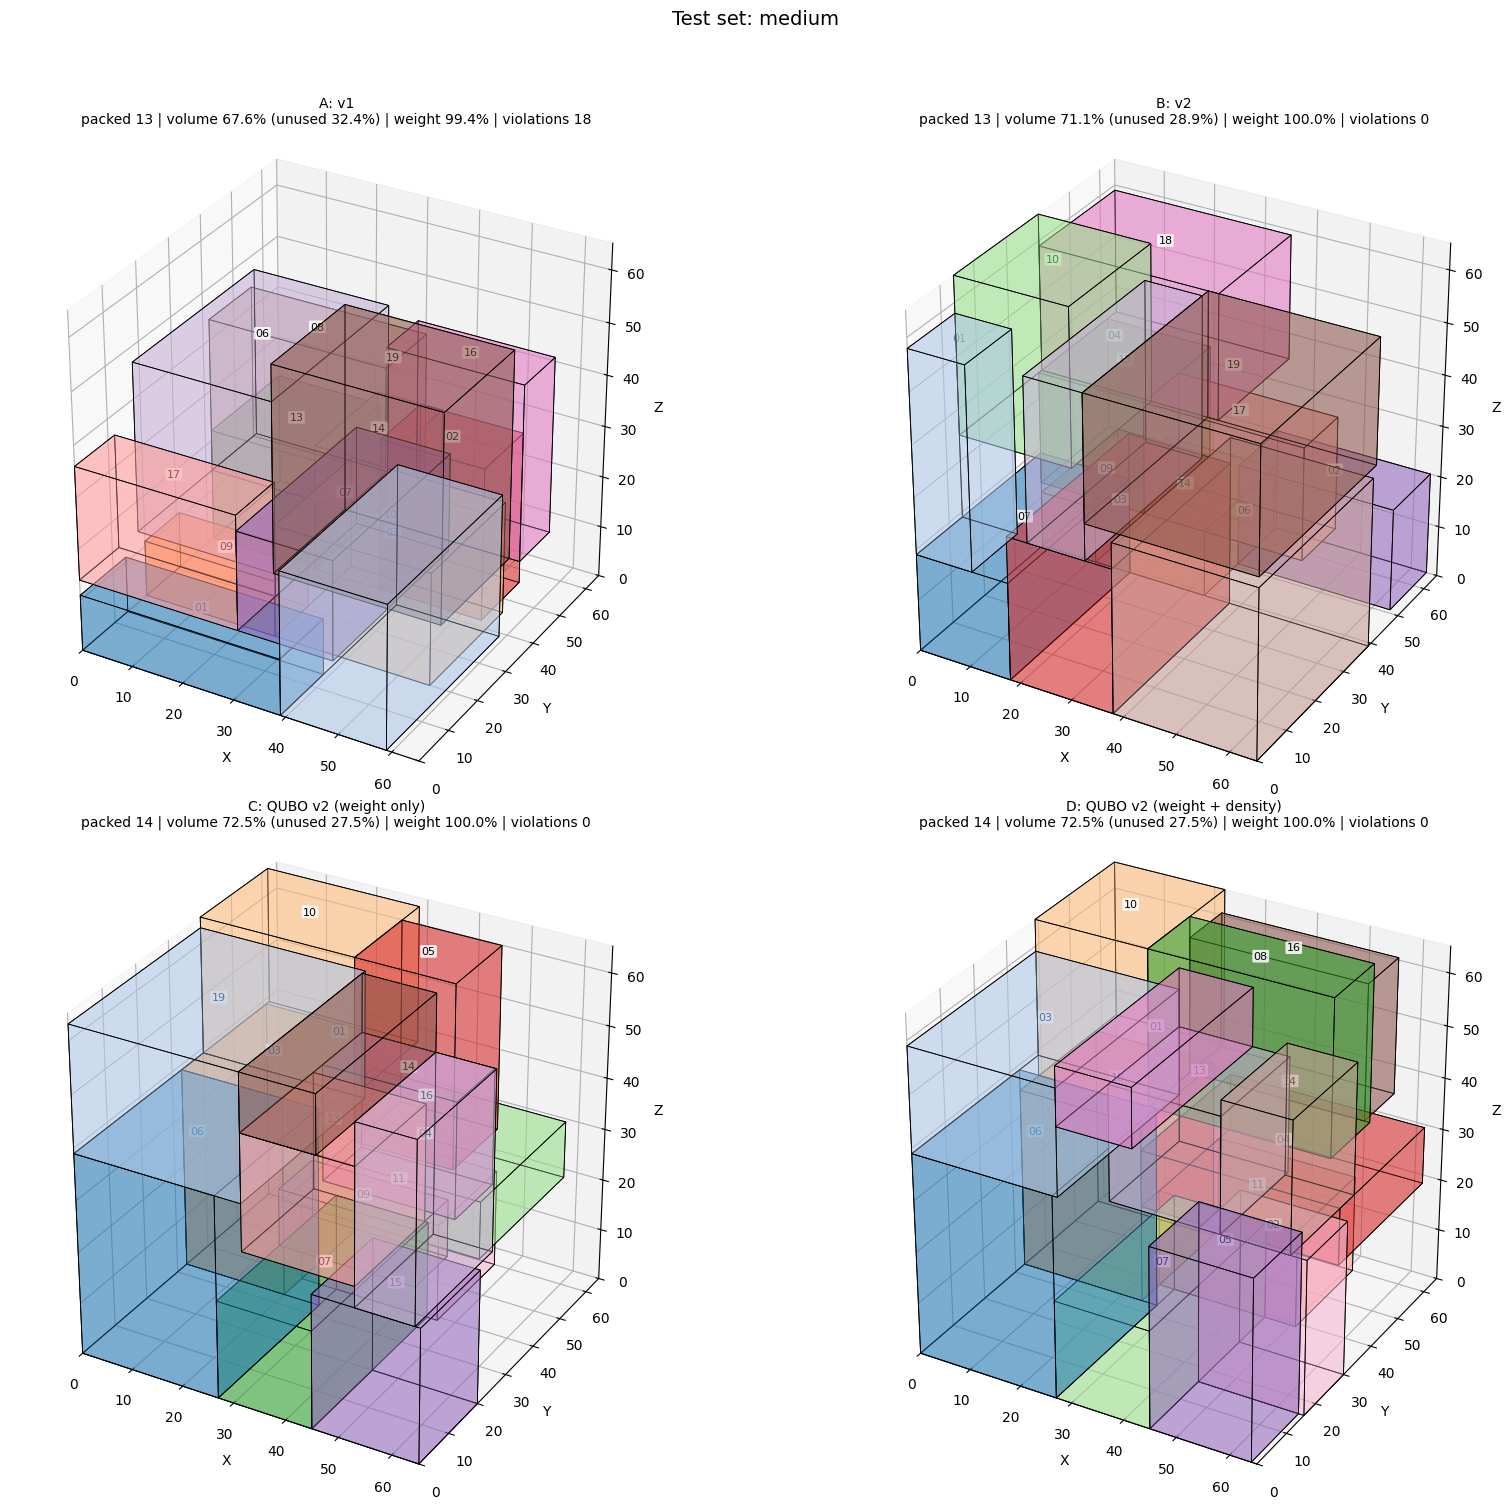

In [16]:
def compare_figure(set_name, label_ids=True, fontsize=8):
    C, P = TESTSETS[set_name]['container'], TESTSETS[set_name]['packages']
    fig = plt.figure(figsize=(18, 15))
    for k, key in enumerate(['A', 'B', 'C', 'D']):
        _, placed, sd = LAYOUTS[(set_name, key)]
        m, v = metrics(placed, C), validate(placed, C, P)
        title = (f"{METHOD_NAMES[key]}\npacked {m['packed']} | volume {m['vol_util']:.1f}% (unused {100-m['vol_util']:.1f}%) | "
                 f"weight {m['wt_util']:.1f}% | violations {v['total_violations']}")
        plot_packing(fig.add_subplot(2, 2, k+1, projection='3d'), placed, C, title, label_ids, fontsize)
    fig.suptitle(f"Test set: {set_name}", fontsize=14, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.97]); fig.savefig(f'results/packing_{set_name}.png', dpi=110); plt.show()

compare_figure('medium', label_ids=True)

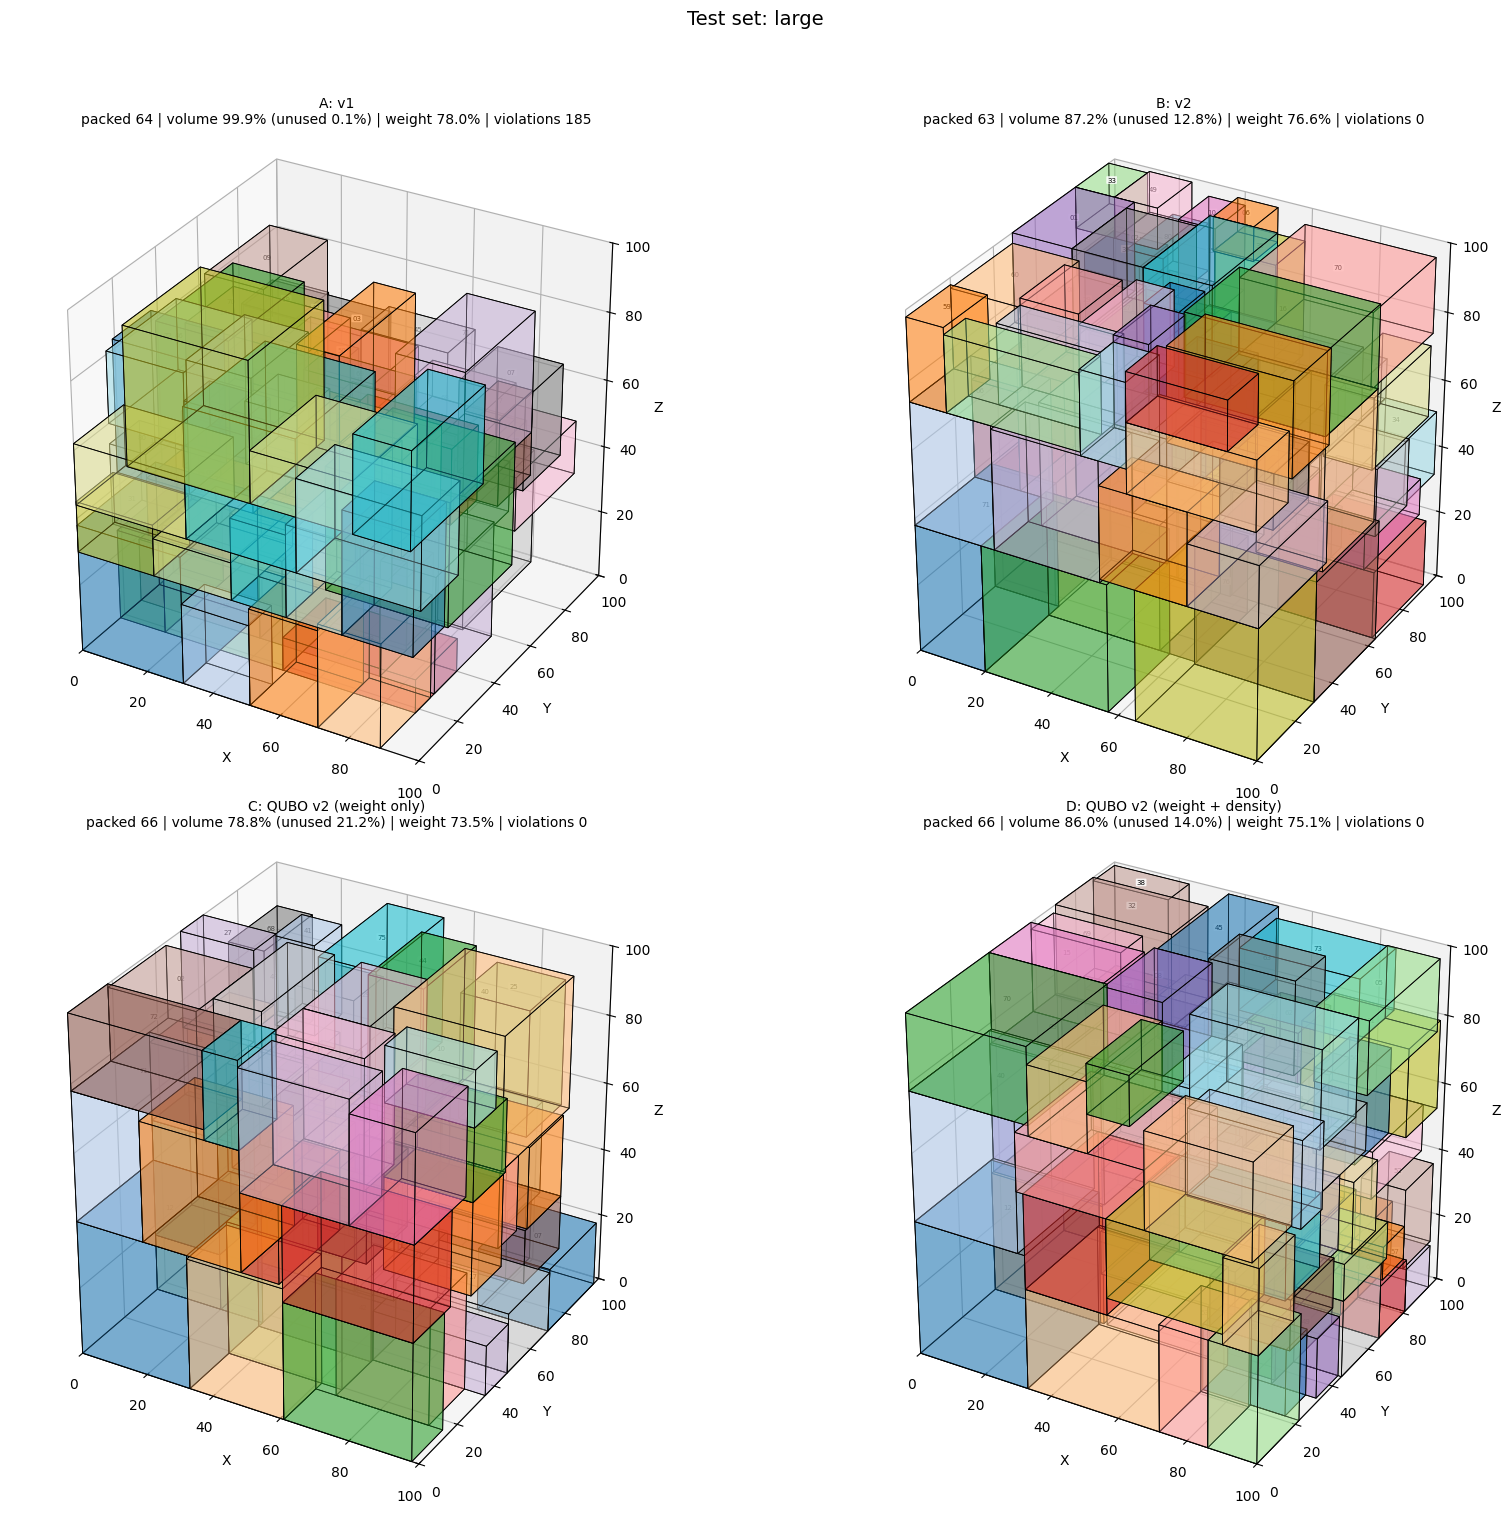

In [17]:
compare_figure('large', label_ids=True, fontsize=5)

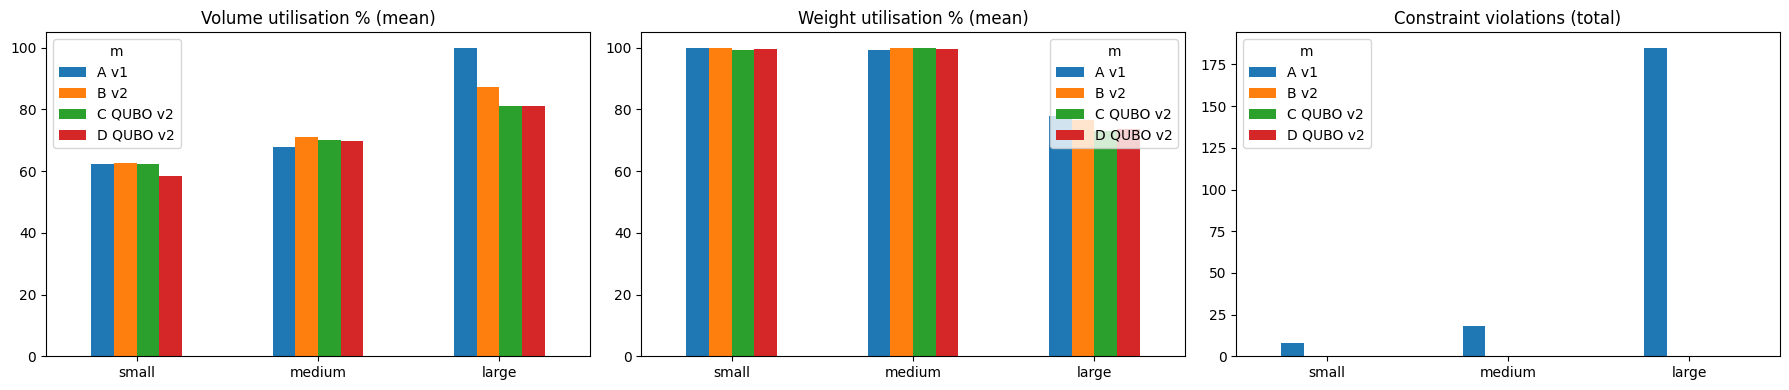

In [18]:
s = summary.reset_index()
short = {v: v.split(':')[0] + ' ' + v.split(': ')[1].split(' (')[0] for v in s['method'].unique()}
s['m'] = s['method'].map(short)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, ttl in zip(axes, ['vol_util_mean', 'wt_util_mean', 'violations'],
                        ['Volume utilisation % (mean)', 'Weight utilisation % (mean)', 'Constraint violations (total)']):
    piv = s.pivot(index='test_set', columns='m', values=col).reindex(['small', 'medium', 'large'])
    piv.plot.bar(ax=ax, rot=0); ax.set_title(ttl); ax.set_xlabel('')
plt.tight_layout(); fig.savefig('results/comparison_chart.png', dpi=120); plt.show()

## Step 7: Conclusions

**The whole journey on the large dataset, in one table.** Every row is one version. Look at the "violations" column and at what each idea fixed or broke.

In [19]:
journey = pd.DataFrame(JOURNEY)
display(journey)
journey.to_csv('results/journey_large_set.csv', index=False)

,version,packed,volume %,weight %,violations,seconds,note
0,v1,64,99.9,78.0,185,0.00,first idea
1,v1.5 extreme points,51,70.1,68.1,0,13.29,support 0.7
2,v2,63,87.2,76.6,0,8.58,best pass: weight/shortside+promote+promote
3,"v2 density-order only (tried, dropped)",65,79.2,74.1,0,7.67,one ordering
4,QUBO v2 (weight only),66,77.6,72.8,0,9.65,"seed 0, density_weight=0"
5,QUBO v2 + density (lambda=1),64,76.2,72.2,0,9.12,seed 0


### What I learned

| Step | What I tried | What it taught me |
|---|---|---|
| 1 | v1 | A great-looking number can be false. Build the checker first. |
| 2 | extreme points | Fixing overlap is not enough. The way I remember free space matters. |
| 3 | v2 | Remember the **empty space**. This gave valid, deterministic, 87% results. |
| 3b | density-only order | A sensible idea can still lose. Test it. |
| 3c | exact solver | v2 is already optimal on small cases, so the hybrid has a hard target to beat. |
| 4 | QUBO v2 (selection) | Small and valid, but not better than v2. |
| 5 | + density in the energy | No clear gain. |
